# Predicción del tiempo de llegada (ETA) de A a B — Experimentación (V1)

Corredor de transporte público de Cusco. Cuando un bus pasa por el punto de control k (A), se predice
cuántos minutos tardará en llegar a **cualquier punto posterior** k+Δ (B), con Δ = 1…17. Un solo modelo
cubre todos los pares A→B; Δ es una variable de entrada.

**Cambios respecto a la versión anterior (V1):**
1. El problema principal pasa de Δ = 1 (siguiente punto) a ETA de A a B (todos los Δ, un solo modelo).
2. La hipótesis se evalúa sobre el MAE global de todos los pares A→B y se reporta la mejora por Δ.
3. Métricas: MAE (principal), RMSE, WAPE, % de predicciones dentro de ±2 min y P90 del error absoluto.
   Se eliminan R² (un predictor trivial por Δ ya alcanza R² ≈ 0,93) y MAPE (se distorsiona en tramos cortos).

Contenido:

1. **Preprocesamiento de tiempos**: pasos por punto de control, limpieza, imputación y headways.
2. **GPS**: anomalías (Isolation Forest), lugares de detención (DBSCAN) y variables por tramo.
   **Altitud y clima**: Open-Meteo con las coordenadas exactas de cada punto de control.
3. **Dataset de modelado**: variables conocidas en el instante a(i,k) y objetivo a(i,k+Δ) − a(i,k).
4. **Experimentos**: E1 comparación de modelos (A→B), E2 error por horizonte Δ, E3 ablación, E4 PCA,
   E5 hiperparámetros y costo, E6 análisis de errores + prueba de Wilcoxon.

Ejecutar desde la raíz del repositorio (lee `Dataset/*.csv`). Escribe tablas en `resultados/`,
figuras en `figuras/` y los mejores modelos en `modelos/` (para la demo).
Tiempo aproximado: ~20 min en una laptop. La primera ejecución descarga el clima de Open-Meteo (requiere
internet) y lo guarda en `datos_externos/`; las siguientes lo leen de ahí.

In [1]:
import json
import time
import warnings
from urllib.request import urlopen
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.cluster import DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import AdaBoostRegressor, HistGradientBoostingRegressor, IsolationForest, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import ParameterSampler
from sklearn.neighbors import BallTree, KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

SEED = 42
DATA = Path("Dataset")
RES, FIG, MOD = Path("resultados"), Path("figuras"), Path("modelos")
for d in (RES, FIG, MOD):
    d.mkdir(exist_ok=True)

DELTAS = list(range(1, 18))  # V1: todos los destinos posteriores (A -> B)
TRAIN_END, VAL_END = "2025-01-22", "2025-01-26"   # partición temporal por días
MAX_DELAY = 60              # |retraso| > 60 min se considera error de registro
MAX_H = 60                  # headways > 60 min = fin de servicio / error
MAX_AGE = 60                # un bus que terminó el tramo hace > 60 min ya no informa del tráfico actual
SLOW = 5                    # km/h: el GPS casi no registra velocidad 0, se usa "detenido o casi detenido"
N_ITER = 6                  # combinaciones de hiperparámetros por modelo
TUNE_N = 60_000             # V1: submuestra de entrenamiento/validación para la búsqueda de hiperparámetros
SLOW_N = 150_000            # V1: submuestra para el ajuste final de KNN/AdaBoost/MLP (costo con ~475 mil filas)
SVM_N = 8000                # submuestra para SVM (costo cuadrático)

## 1. Preprocesamiento de `Times.csv`

Cada fila es una vuelta con tres arreglos de 18 valores (hora programada, hora real y retraso).
Se convierte a una fila por **paso** (vuelta i, punto de control k). Reglas de limpieza:

- `end_time = 00:00:00` → el paso **no fue registrado** (es el origen del `-` en `difference_time`).
- |retraso| > 60 min → error de registro.
- Hora real menor que la de un punto anterior de la misma vuelta → error (no monotónico).
- Isolation Forest sobre el retraso y la desviación del tramo para marcar anomalías restantes.

In [2]:
t = pd.read_csv(DATA / "Times.csv", dtype={"vehicle_id_id": str})
arr = ["start_time", "end_time", "difference_time"]
for c in arr:
    t[c] = t[c].str.strip("{}").str.split(",")
p = t.explode(arr).reset_index(drop=True)
p["k"] = p.groupby("id").cumcount() + 1
p = p.rename(columns={"id": "trip", "vehicle_id_id": "veh"})
p["s"] = pd.to_timedelta(p.start_time).dt.total_seconds() / 60   # minutos desde medianoche
p["a"] = pd.to_timedelta(p.end_time).dt.total_seconds() / 60
p = p[["trip", "date", "veh", "lap", "k", "s", "a"]].sort_values(["trip", "k"]).reset_index(drop=True)

limpieza = {"pasos totales": len(p)}
p.loc[p.a == 0, "a"] = np.nan
limpieza["no registrados (00:00:00)"] = int(p.a.isna().sum())
p["delay"] = p.a - p.s
bad = p.delay.abs() > MAX_DELAY
limpieza[f"|retraso| > {MAX_DELAY} min"] = int(bad.sum())
p.loc[bad, ["a", "delay"]] = np.nan
prev_max = p.groupby("trip").a.cummax().groupby(p.trip).shift().groupby(p.trip).ffill()
bad = p.a < prev_max
limpieza["no monotónicos"] = int(bad.sum())
p.loc[bad, ["a", "delay"]] = np.nan

# desviación del tramo k-1 -> k respecto a lo programado (= cambio de retraso)
p["ddelay"] = p.delay - p.groupby("trip").delay.shift()
ok = p[["delay", "ddelay"]].notna().all(axis=1)
iso_p = IsolationForest(contamination=0.001, random_state=SEED).fit(p.loc[ok, ["delay", "ddelay"]])
bad = pd.Series(False, index=p.index)
bad[ok] = iso_p.predict(p.loc[ok, ["delay", "ddelay"]]) == -1
limpieza["anomalías Isolation Forest"] = int(bad.sum())
p.loc[bad, ["a", "delay"]] = np.nan
limpieza["pasos válidos"] = int(p.a.notna().sum())
pd.Series(limpieza, name="pasos").to_frame()

,pasos
pasos totales,84726
no registrados (00:00:00),7746
|retraso| > 60 min,156
no monotónicos,0
anomalías Isolation Forest,71
pasos válidos,76753


**Imputación y headway.** El headway con el bus de adelante es una variable útil (un bus con más
tiempo detrás del anterior encuentra más pasajeros y demora más). Si al bus de adelante le falta un
paso, el headway saldría inflado; por eso el retraso faltante se interpola dentro de la vuelta
(máximo 2 puntos seguidos). Los pasos imputados solo se usan para calcular headways, nunca como objetivo.

In [3]:
p["delay_i"] = p.groupby("trip").delay.transform(lambda d: d.interpolate(limit=2, limit_area="inside"))
p["a_i"] = p.s + p.delay_i
p["imp"] = p.a.isna() & p.a_i.notna()
print(f"pasos imputados: {p.imp.sum()}  | sin dato tras imputar: {p.a_i.isna().sum()}")

q = p[p.a_i.notna()].sort_values(["date", "k", "a_i"])
g = q.groupby(["date", "k"])
q["h"] = q.a_i - g.a_i.shift()
q["hp"] = q.s - g.s.shift()
q.loc[~(q.h.between(0, MAX_H) & q.hp.between(0, MAX_H, inclusive="right")), "h"] = np.nan
p = p.merge(q[["trip", "k", "h"]], on=["trip", "k"], how="left")
print(f"headways válidos: {p.h.notna().sum()}")

pasos imputados: 1398  | sin dato tras imputar: 6575
headways válidos: 76484


### Análisis exploratorio del tiempo de tramo
Tiempo real T = a(i,k+1) − a(i,k) frente al programado s(i,k+1) − s(i,k), solo con pasos reales.

tramos válidos: 70777 | tiempo medio 9.67 min | error del horario (MAE) 1.56 min | σ de la desviación 2.16 min
vuelta completa: programada 161 min, real 164 min (mediana); P10–P90 real 148–179 min
desviación media por hora (min): {4: -1.05, 5: -1.24, 6: -0.42, 7: 0.0, 8: 0.09, 9: 0.17, 10: 0.32, 11: 0.38, 12: 0.3, 13: 0.16, 14: 0.18, 15: 0.26, 16: 0.36, 17: 0.54, 18: 0.88, 19: 0.88, 20: 0.52, 21: 0.03, 22: -0.42}


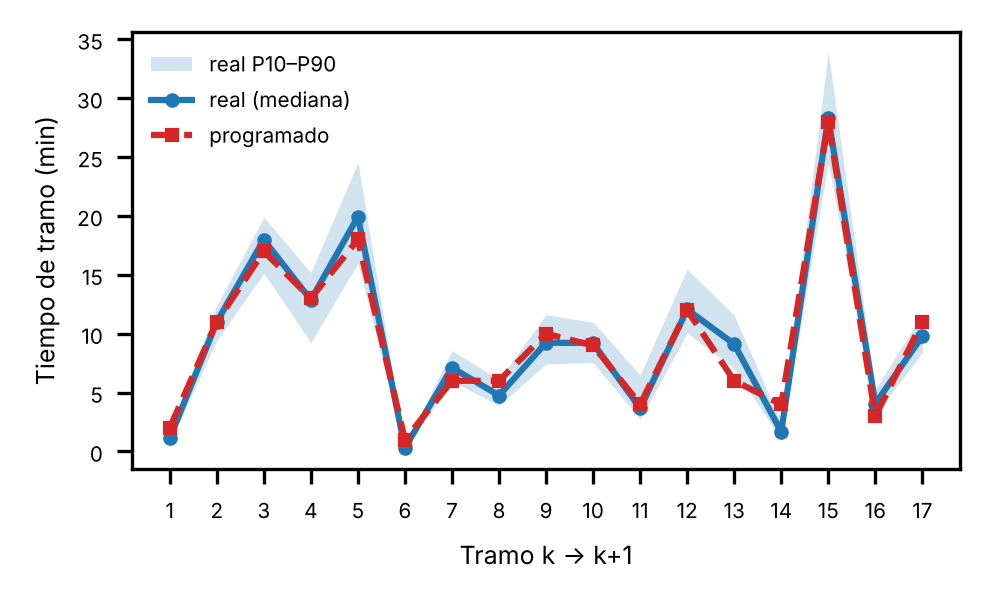

k,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
prog,2.00,11.00,17.00,13.00,18.00,1.00,6.00,6.00,10.00,9.00,4.00,12.00,6.00,4.00,28.00,3.00,11.00
real,1.12,11.00,17.98,12.87,19.93,0.30,7.12,4.75,9.23,9.20,3.67,12.06,9.12,1.67,28.32,4.05,9.80
p10,0.77,9.42,15.14,9.23,15.98,0.22,5.98,3.90,7.43,7.55,2.72,10.05,7.03,0.98,24.52,3.17,8.38
p90,1.53,12.41,19.88,15.18,24.53,0.43,8.57,6.10,11.62,10.97,6.50,15.49,11.57,2.47,33.90,5.28,11.71
mae_horario,0.87,0.94,1.59,1.46,2.39,0.69,1.26,1.34,1.47,1.11,1.35,1.73,3.16,2.12,2.41,1.21,1.44


In [4]:
p = p.sort_values(["trip", "k"]).reset_index(drop=True)
gt = p.groupby("trip")
seg_t = p.assign(T=gt.a.shift(-1) - p.a, Tp=gt.s.shift(-1) - p.s).dropna(subset=["T"])
seg_t = seg_t[seg_t.k < 18]
seg_t["dev"] = seg_t["T"] - seg_t.Tp
vuelta = p[p.k.isin([1, 18])].pivot_table(index="trip", columns="k", values=["a", "s"])
vr = (vuelta[("a", 18)] - vuelta[("a", 1)]).dropna()
vp = (vuelta[("s", 18)] - vuelta[("s", 1)]).loc[vr.index]
print(f"tramos válidos: {len(seg_t)} | tiempo medio {seg_t['T'].mean():.2f} min | "
      f"error del horario (MAE) {seg_t.dev.abs().mean():.2f} min | σ de la desviación {seg_t.dev.std():.2f} min")
print(f"vuelta completa: programada {vp.median():.0f} min, real {vr.median():.0f} min (mediana); "
      f"P10–P90 real {vr.quantile(.1):.0f}–{vr.quantile(.9):.0f} min")
by_h = seg_t.assign(hora=(seg_t.s // 60).astype(int)).groupby("hora").dev.mean()
print("desviación media por hora (min):", by_h.round(2).to_dict())

by_k = seg_t.groupby("k").agg(prog=("Tp", "median"), real=("T", "median"),
                              p10=("T", lambda x: x.quantile(.1)), p90=("T", lambda x: x.quantile(.9)),
                              mae_horario=("dev", lambda x: x.abs().mean()))
fig, ax = plt.subplots(figsize=(3.4, 2.1), dpi=300)
ax.fill_between(by_k.index, by_k.p10, by_k.p90, color="tab:blue", alpha=0.2, lw=0, label="real P10–P90")
ax.plot(by_k.index, by_k.real, "o-", ms=2.5, color="tab:blue", label="real (mediana)")
ax.plot(by_k.index, by_k.prog, "s--", ms=2.5, color="tab:red", label="programado")
ax.set_xlabel("Tramo k → k+1", fontsize=6); ax.set_ylabel("Tiempo de tramo (min)", fontsize=6)
ax.set_xticks(range(1, 18)); ax.tick_params(labelsize=5); ax.legend(fontsize=5, frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig2_tramos.png"); plt.show()
by_k.round(2).T

## 2. Preprocesamiento de `Monitoring.csv` (GPS)

- Se eliminan registros duplicados (mismo vehículo, fecha y hora).
- **Isolation Forest** sobre (latitud, longitud, velocidad) elimina saltos de GPS y velocidades imposibles.
- **DBSCAN** (distancia haversine, eps = 25 m) sobre los registros detenidos (≤ 5 km/h; el equipo GPS casi
  no registra velocidad 0, solo 0,6 % de los registros) identifica los lugares donde los buses se
  detienen de forma recurrente (paraderos reales, terminal, semáforos).

In [5]:
m = pd.read_csv(DATA / "Monitoring.csv", dtype={"vehicle_id_id": str},
                usecols=["date", "time", "latitude", "longitude", "speed", "vehicle_id_id"])
m = m.rename(columns={"vehicle_id_id": "veh"})
n0 = len(m)
m = m.drop_duplicates(["veh", "date", "time"])
m["t"] = pd.to_timedelta(m.time).dt.total_seconds() / 60
iso_g = IsolationForest(contamination=0.005, random_state=SEED, n_jobs=-1)
out = iso_g.fit_predict(m[["latitude", "longitude", "speed"]]) == -1
print(f"GPS: {n0} registros, {n0 - len(m)} duplicados, {out.sum()} anomalías (Isolation Forest)")
m = m[~out].reset_index(drop=True)

GPS: 1630431 registros, 6783 duplicados, 8104 anomalías (Isolation Forest)


DBSCAN: 104 lugares de detención recurrentes; 92.9% de los registros detenidos cae en uno


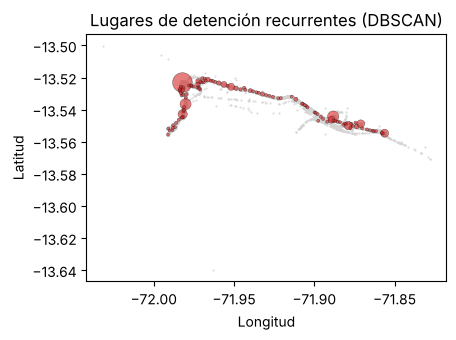

In [6]:
EPS = 25 / 6_371_000   # 25 m en radianes
stop = m[m.speed <= SLOW]
samp = stop.sample(min(40_000, len(stop)), random_state=SEED)
Xs = np.radians(samp[["latitude", "longitude"]].to_numpy())
db = DBSCAN(eps=EPS, min_samples=40, metric="haversine", algorithm="ball_tree").fit(Xs)
core, core_lab = Xs[db.core_sample_indices_], db.labels_[db.core_sample_indices_]
# asignar todos los registros detenidos al cluster del punto núcleo más cercano (si está a < eps)
dist, idx = BallTree(core, metric="haversine").query(np.radians(stop[["latitude", "longitude"]].to_numpy()), k=1)
m["par"] = -1
m.loc[stop.index, "par"] = np.where(dist[:, 0] <= EPS, core_lab[idx[:, 0]], -1)
print(f"DBSCAN: {len(set(core_lab))} lugares de detención recurrentes; "
      f"{(m.loc[stop.index, 'par'] >= 0).mean():.1%} de los registros detenidos cae en uno")
centros = m[m.par >= 0].groupby("par")[["latitude", "longitude"]].median()
centros["registros"] = m[m.par >= 0].groupby("par").size()
centros.to_csv(RES / "paraderos_dbscan.csv")

fig, ax = plt.subplots(figsize=(7, 3.5))
bg = m.sample(60_000, random_state=SEED)
ax.scatter(bg.longitude, bg.latitude, s=0.2, c="lightgray", rasterized=True)
ax.scatter(centros.longitude, centros.latitude, s=np.clip(centros.registros / 50, 5, 200),
           c="tab:red", alpha=0.6, edgecolor="k", linewidth=0.3)
ax.set(xlabel="Longitud", ylabel="Latitud", title="Lugares de detención recurrentes (DBSCAN)")
ax.set_aspect("equal")
fig.tight_layout(); fig.savefig(FIG / "exp_dbscan_paraderos.png", dpi=200); plt.show()

**Variables GPS por tramo.** Cada registro GPS se asigna al tramo que termina en el siguiente paso
del mismo vehículo (k−1 → k), con `merge_asof`. Por tramo se calcula: velocidad media, fracción de
registros detenidos, fracción detenida en lugares DBSCAN y número de lugares DBSCAN distintos.

In [7]:
passes = p.loc[p.a_i.notna(), ["veh", "date", "a_i", "trip", "k"]].sort_values("a_i")
mg = pd.merge_asof(m.sort_values("t"), passes, left_on="t", right_on="a_i", by=["veh", "date"],
                   direction="forward", tolerance=60).dropna(subset=["trip"])
mg["stop"] = mg.speed <= SLOW
mg["stop_par"] = mg.stop & (mg.par >= 0)
seg = mg.groupby(["trip", "k"]).agg(v=("speed", "mean"), stop=("stop", "mean"),
                                    stop_par=("stop_par", "mean"),
                                    npar=("par", lambda s: s[s >= 0].nunique())).reset_index()
seg["trip"] = seg.trip.astype(p.trip.dtype)
seg["k"] = seg.k.astype(int)
print(f"tramos con GPS: {len(seg)} de {p.a_i.notna().sum()}")
seg.describe().round(2)

tramos con GPS: 76928 de 78151


,trip,k,v,stop,stop_par,npar
count,76928.00,76928.00,76928.00,76928.00,76928.00,76928.00
mean,22430.05,9.43,23.86,0.03,0.03,0.41
std,9155.28,5.20,5.67,0.07,0.07,0.66
min,6653.00,1.00,0.00,0.00,0.00,0.00
25%,14284.00,5.00,19.83,0.00,0.00,0.00
50%,22359.00,9.00,23.76,0.00,0.00,0.00
75%,30186.25,14.00,27.59,0.04,0.04,1.00
max,38832.00,18.00,58.00,1.00,1.00,7.00


### Altitud y clima (Open-Meteo)

Se consulta Open-Meteo con las coordenadas **exactas** de los 18 puntos de control (mediana del GPS en
el instante de paso), no con un punto genérico de la ciudad:

- **Altitud**: API de elevación de Open-Meteo (modelo digital de elevación de 90 m) en cada punto.
- **Clima**: API histórica (reanálisis ERA5), hora local de Lima. Se envía la altitud de cada punto para
  que la temperatura se corrija por altura, y `cell_selection=nearest` para usar la celda de la grilla
  más cercana a cada punto. La grilla del modelo tiene ~7 km, así que puntos cercanos comparten celda;
  la tabla de verificación muestra a qué distancia quedó la celda de cada punto.

Variables: temperatura, humedad relativa, precipitación de la hora y de las últimas 3 horas, nubosidad y
viento. A cada paso se le asigna el clima de su punto de control en la hora en que ocurrió.

In [8]:
CLIMA = Path("datos_externos/clima_open_meteo.csv")
PUNTOS = Path("datos_externos/puntos_control_clima.csv")
VARS = ["temperature_2m", "relative_humidity_2m", "precipitation", "cloud_cover", "wind_speed_10m"]
pc = p.loc[p.a.notna(), ["date", "veh", "k", "a"]].sort_values("a")
cp = pd.merge_asof(pc, m[["date", "veh", "t", "latitude", "longitude"]].sort_values("t"), left_on="a", right_on="t",
                   by=["date", "veh"], tolerance=1.0, direction="nearest").groupby("k")[["latitude", "longitude"]].median()
if not (CLIMA.exists() and PUNTOS.exists()):
    lat, lon = ",".join(cp.latitude.round(5).astype(str)), ",".join(cp.longitude.round(5).astype(str))
    cp["alt"] = json.load(urlopen(f"https://api.open-meteo.com/v1/elevation?latitude={lat}&longitude={lon}", timeout=60))["elevation"]
    url = (f"https://archive-api.open-meteo.com/v1/archive?latitude={lat}&longitude={lon}"
           f"&elevation={','.join(cp.alt.astype(str))}&cell_selection=nearest"
           f"&start_date={m.date.min()}&end_date={m.date.max()}&hourly={','.join(VARS)}&timezone=America%2FLima")
    locs = json.load(urlopen(url, timeout=120))
    cp["lat_celda"] = [loc["latitude"] for loc in locs]
    cp["lon_celda"] = [loc["longitude"] for loc in locs]
    cp["alt_usada"] = [loc["elevation"] for loc in locs]
    PUNTOS.parent.mkdir(exist_ok=True)
    cp.to_csv(PUNTOS)
    pd.concat([pd.DataFrame(loc["hourly"]).assign(k=k_) for k_, loc in zip(cp.index, locs)]).to_csv(CLIMA, index=False)
cp = pd.read_csv(PUNTOS, index_col="k")
cp.to_csv(RES / "puntos_control.csv")

# verificación: cada punto usa sus propias coordenadas y altitud
rad = np.radians
cp["dist_celda_km"] = 2 * 6371 * np.arcsin(np.sqrt(
    np.sin(rad(cp.lat_celda - cp.latitude) / 2) ** 2
    + np.cos(rad(cp.latitude)) * np.cos(rad(cp.lat_celda)) * np.sin(rad(cp.lon_celda - cp.longitude) / 2) ** 2))
assert (cp.alt_usada == cp.alt).all(), "Open-Meteo no usó la altitud enviada"
print(f"{len(cp)} puntos consultados | {len(cp[['lat_celda', 'lon_celda']].drop_duplicates())} celdas de la grilla | "
      f"distancia punto → celda: media {cp.dist_celda_km.mean():.1f} km, máx. {cp.dist_celda_km.max():.1f} km | "
      f"altitud {cp.alt.min():.0f}–{cp.alt.max():.0f} m")
cp.round(4)

18 puntos consultados | 2 celdas de la grilla | distancia punto → celda: media 3.0 km, máx. 5.0 km | altitud 3185–3519 m


,latitude,longitude,alt,lat_celda,lon_celda,alt_usada,dist_celda_km
k,,,,,,,
1,-13.5552,-71.8568,3188.0,-13.5325,-71.8681,3188.0,2.8031
2,-13.5535,-71.8607,3185.0,-13.5325,-71.8681,3185.0,2.4669
3,-13.5446,-71.8883,3242.0,-13.5325,-71.8681,3242.0,2.5591
4,-13.5288,-71.9372,3313.0,-13.5325,-71.9505,3313.0,1.5041
5,-13.5216,-71.9651,3367.0,-13.5325,-71.9505,3367.0,1.9880
6,-13.5256,-71.9833,3412.0,-13.5325,-71.9505,3412.0,3.6273
7,-13.5259,-71.9827,3417.0,-13.5325,-71.9505,3417.0,3.5510
8,-13.5359,-71.9804,3370.0,-13.5325,-71.9505,3370.0,3.2478
9,-13.5442,-71.9821,3377.0,-13.5325,-71.9505,3377.0,3.6531


In [9]:
cl = pd.read_csv(CLIMA).sort_values(["k", "time"])
cl["date"], cl["hora_c"] = cl.time.str[:10], cl.time.str[11:13].astype(int)
cl["precip_3h"] = cl.groupby("k").precipitation.transform(lambda x: x.rolling(3, min_periods=1).sum())
cl = cl.rename(columns={"temperature_2m": "temp", "relative_humidity_2m": "hum", "precipitation": "precip",
                        "cloud_cover": "nubes", "wind_speed_10m": "viento"})
cl = cl[["k", "date", "hora_c", "temp", "hum", "precip", "precip_3h", "nubes", "viento"]]
print(f"clima: {len(cl)} registros horarios; {cl.groupby('k').precip.sum().nunique()} series de precipitación distintas "
      f"(celdas de la grilla; la temperatura se corrige por altitud en cada punto); "
      f"horas con lluvia (≥ 0,1 mm): {(cl.precip >= 0.1).mean():.1%}")

# efecto de la lluvia sobre el tiempo de tramo (análisis exploratorio)
st = seg_t.assign(hora_c=(seg_t.a // 60).astype(int)).merge(cl, on=["k", "date", "hora_c"], how="left")
st["lluvia"] = pd.cut(st.precip, [-0.01, 0.0999, 1, 100], labels=["seco", "lluvia débil (0,1–1 mm)", "lluvia (> 1 mm)"])
st.groupby("lluvia", observed=True).agg(tramos=("dev", "size"), desviacion_media=("dev", "mean"),
                                         mae_horario=("dev", lambda x: x.abs().mean())).round(3)

clima: 13824 registros horarios; 2 series de precipitación distintas (celdas de la grilla; la temperatura se corrige por altitud en cada punto); horas con lluvia (≥ 0,1 mm): 46.7%


,tramos,desviacion_media,mae_horario
lluvia,,,
seco,33005,0.238,1.595
"lluvia débil (0,1–1 mm)",31947,0.216,1.506
lluvia (> 1 mm),5825,0.351,1.691


## 3. Dataset de modelado

Para cada paso **real** del bus i por el punto k se predice y = a(i,k+Δ) − a(i,k) con variables
conocidas en el instante a(i,k):

| Grupo | Variables |
|---|---|
| Bus i | retraso δ(i,k), cambio de retraso en el último tramo, tiempo real del último tramo, headway con el bus de adelante, vuelta |
| Buses recientes | tiempo del último bus que **terminó** el mismo tramo antes de a(i,k), media de los 3 últimos y hace cuánto lo terminó |
| GPS | velocidad media y fracción detenida del bus i en su último tramo y del último bus en el tramo a predecir |
| DBSCAN | fracción detenida en paraderos y n.º de paraderos del bus i (último tramo) y del último bus (tramo a predecir) |
| Clima | temperatura, humedad, precipitación (hora y 3 h), nubosidad y viento en el punto k a la hora del paso |
| Altitud | altitud del punto k y desnivel hasta el punto k+Δ (m) |
| Contexto | k (origen A), **Δ (n.º de puntos hasta el destino B)**, hora, día de la semana, tiempo programado de A a B, vehículo |

In [10]:
key = ["trip", "k"]
p = p.merge(seg, on=key, how="left").sort_values(key).reset_index(drop=True)
gt = p.groupby("trip")
p["T_prev"] = p.a - gt.a.shift()
p["ddelay_k"] = p.delay_i - gt.delay_i.shift()
p = p.rename(columns={"delay": "delay_k", "h": "h_k", "v": "v_i", "stop": "stop_i",
                      "stop_par": "stoppar_i", "npar": "npar_i"})
segj = seg.rename(columns={"trip": "trip_c", "k": "kc", "v": "v_last", "stop": "stop_last", "npar": "npar_last"})
segj["trip_c"] = segj.trip_c.astype(float)   # merge_asof deja trip_c como float (hay NaN)

rows = []
for D in DELTAS:
    b = p[p.a.notna() & (p.k + D <= 18)].copy()
    b["delta"], b["kt"] = D, b.k + D
    nxt = p[["trip", "k", "a", "s"]].rename(columns={"k": "kt", "a": "a_t", "s": "s_t"})
    b = b.merge(nxt, on=["trip", "kt"], how="inner").dropna(subset=["a_t"])
    b["y"], b["sp"] = b.a_t - b.a, b.s_t - b.s
    # buses que ya terminaron el mismo tramo k -> k+Δ: el más reciente antes de a(i,k)
    comp = b[["date", "k", "a_t", "y", "trip"]].rename(columns={"a_t": "c", "y": "T_last", "trip": "trip_c"})
    comp = comp.sort_values("c")
    comp["T_roll3"] = comp.groupby(["date", "k"]).T_last.transform(lambda x: x.rolling(3, min_periods=1).mean())
    b = pd.merge_asof(b.sort_values("a"), comp, left_on="a", right_on="c", by=["date", "k"],
                      direction="backward", allow_exact_matches=False)
    b["age_last"] = b.a - b.c
    stale = b.age_last > MAX_AGE
    b.loc[stale, ["T_last", "T_roll3", "age_last", "trip_c"]] = np.nan
    b["kc"] = b.k + 1   # GPS del último bus en el primer tramo de su recorrido k -> k+1
    b = b.merge(segj[["trip_c", "kc", "v_last", "stop_last", "npar_last"]], on=["trip_c", "kc"], how="left")
    rows.append(b)
D_all = pd.concat(rows, ignore_index=True)
D_all["hour"] = D_all.s / 60
D_all["dow"] = pd.to_datetime(D_all.date).dt.dayofweek
D_all["hora_c"] = (D_all.a // 60).astype(int)
D_all = D_all.merge(cl, on=["k", "date", "hora_c"], how="left")
D_all["alt"] = D_all.k.map(cp.alt)
D_all["desnivel"] = D_all.kt.map(cp.alt) - D_all.alt
D_all["split"] = np.where(D_all.date <= TRAIN_END, "train", np.where(D_all.date <= VAL_END, "val", "test"))

G_I = ["delay_k", "ddelay_k", "T_prev", "h_k", "lap"]
G_REC = ["T_last", "T_roll3", "age_last"]
G_GPS = ["v_i", "stop_i", "v_last", "stop_last"]
G_DB = ["stoppar_i", "npar_i", "npar_last"]
G_CLIMA = ["temp", "hum", "precip", "precip_3h", "nubes", "viento"]
G_ALT = ["alt", "desnivel"]
G_CTX = ["k", "delta", "hour", "dow", "sp"]
CAT = ["veh"]
NUM = G_I + G_REC + G_GPS + G_DB + G_CLIMA + G_ALT + G_CTX
D_all[list(dict.fromkeys(["date", "split", "delta", "trip", "veh", "s", "a"] + NUM + ["y"]))].to_pickle(RES / "dataset_modelo.pkl")

print(D_all.groupby(["delta", "split"]).size().unstack())
D_all[NUM + ["y"]].describe().T.round(2)

split   test  train    val
delta                     
1      16889  43823  10065
2      15958  41427   9507
3      14931  38831   8921
4      13853  36055   8279
5      12792  33317   7642
6      11733  30592   7021
7      10675  27867   6393
8       9639  25191   5777
9       8592  22461   5153
10      7559  19769   4540
11      6555  17154   3941
12      5539  14554   3344
13      4542  11991   2764
14      3605   9543   2201
15      2578   6858   1587
16      1650   4463   1039
17       886   2457    566


,count,mean,std,min,25%,50%,75%,max
delay_k,623069.0,0.05,3.88,-54.15,-1.58,-0.25,1.35,49.50
ddelay_k,550943.0,0.21,1.96,-8.37,-0.90,-0.22,1.13,56.35
T_prev,546914.0,9.39,6.77,0.08,3.70,9.20,13.28,62.35
h_k,614838.0,5.63,2.56,0.00,4.03,5.30,6.90,38.42
lap,623069.0,2.75,1.37,1.00,2.00,3.00,4.00,8.00
T_last,588763.0,55.81,37.95,0.08,25.83,49.62,80.40,201.83
T_roll3,588763.0,55.79,37.85,0.17,25.90,49.67,80.22,193.89
age_last,588763.0,3.89,3.48,0.02,1.52,3.15,5.27,59.77
v_i,611410.0,24.31,5.79,0.00,20.17,24.06,28.00,56.50
stop_i,611410.0,0.03,0.07,0.00,0.00,0.00,0.04,1.00


## 4. Modelos, referencias y protocolo

- **Referencias**:
  - *horario*: ŷ = tiempo programado del tramo.
  - *histórico*: ŷ = tiempo medio de A a B a esa hora en entrenamiento (k × Δ × hora).
  - *último bus*: ŷ = tiempo del último bus que terminó el mismo trayecto A→B (si no hay, el horario).
- **Modelos** (scikit-learn): Ridge, KNN, árbol de decisión, SVM-RBF (submuestra), Random Forest,
  AdaBoost, Gradient Boosting (HistGradientBoosting) y MLP.
- **Preprocesamiento**: imputación por mediana + estandarización (numéricas) y one-hot (vehículo).
- **Ajuste**: `N_ITER` combinaciones de la Tabla II evaluadas en validación (MAE) sobre submuestras de
  `TUNE_N` filas; el mejor se reentrena con entrenamiento + validación y se evalúa **una vez** en prueba.
  KNN, AdaBoost y MLP se reentrenan con una submuestra de `SLOW_N` filas por costo; SVM con `SVM_N`.
- **Métricas**: MAE (principal), RMSE, WAPE = Σ|error| / Σy, % de predicciones con |error| ≤ 2 min y
  percentil 90 del error absoluto. No se usa R² (la duración depende casi solo de Δ: un predictor
  trivial ya logra R² ≈ 0,93) ni MAPE (se dispara en tramos de 1–2 min y contradice al MAE).

In [11]:
def prep(num, pca=False):
    steps_num = [("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]
    ct = ColumnTransformer([("num", Pipeline(steps_num), num),
                            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    return [("prep", ct)] + ([("pca", PCA(n_components=0.95, random_state=SEED))] if pca else [])


REG = {
    "Ridge": (Ridge(), {"alpha": [0.01, 0.1, 1, 10, 100]}),
    "KNN": (KNeighborsRegressor(n_jobs=-1), {"n_neighbors": [5, 15, 51], "weights": ["uniform", "distance"]}),
    "Árbol": (DecisionTreeRegressor(random_state=SEED), {"max_depth": [5, 10, 20], "min_samples_leaf": [1, 20, 100]}),
    "SVM": (SVR(), {"C": [0.1, 1, 10], "gamma": [0.01, 0.1, "scale"]}),
    "RandomForest": (RandomForestRegressor(random_state=SEED, n_jobs=-1),
                     {"n_estimators": [200, 500], "max_depth": [10, 20, None], "min_samples_leaf": [1, 5, 20]}),
    "AdaBoost": (AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), random_state=SEED),
                 {"n_estimators": [100, 300], "learning_rate": [0.1, 1.0]}),
    "GradBoost": (HistGradientBoostingRegressor(random_state=SEED, max_iter=1000, early_stopping=True),
                  {"learning_rate": [0.03, 0.1], "max_depth": [4, 6, 8]}),
    "MLP": (MLPRegressor(random_state=SEED, early_stopping=True, max_iter=300),
            {"hidden_layer_sizes": [(64, 32), (128, 64, 32)], "alpha": [1e-4, 1e-3], "learning_rate_init": [1e-3, 1e-4]}),
}


def metrics(y, yhat):
    y, yhat = np.asarray(y), np.asarray(yhat)
    e = np.abs(y - yhat)
    return {"MAE": mean_absolute_error(y, yhat), "RMSE": root_mean_squared_error(y, yhat),
            "WAPE_%": 100 * e.sum() / y.sum(), "dentro_2min_%": 100 * (e <= 2).mean(),
            "P90_error": np.quantile(e, 0.9)}


def baselines(d_fit, d):
    """Referencias sin aprendizaje; el histórico se calcula solo con d_fit (sin mirar prueba)."""
    hist_kdh = d_fit.groupby(["k", "delta", d_fit.hour.astype(int)]).y.mean()
    hist_kd = d_fit.groupby(["k", "delta"]).y.mean()
    idx = pd.MultiIndex.from_arrays([d.k, d.delta, d.hour.astype(int)])
    idx2 = pd.MultiIndex.from_arrays([d.k, d.delta])
    hist = pd.Series(hist_kdh.reindex(idx).to_numpy(), index=d.index)
    hist = hist.fillna(pd.Series(hist_kd.reindex(idx2).to_numpy(), index=d.index))
    return {"Ref. horario": d.sp.to_numpy(), "Ref. histórico": hist.to_numpy(),
            "Ref. último bus": d.T_last.fillna(d.sp).to_numpy()}


def fit(name, est, params, d, num, pca=False):
    """Entrena el pipeline con los parámetros dados; SVM usa una submuestra."""
    pipe = Pipeline(prep(num, pca) + [("model", est)]).set_params(**{f"model__{k}": v for k, v in params.items()})
    if name == "SVM" and len(d) > SVM_N:
        d = d.sample(SVM_N, random_state=SEED)
    elif name in ("KNN", "AdaBoost", "MLP") and len(d) > SLOW_N:
        d = d.sample(SLOW_N, random_state=SEED)
    t0 = time.perf_counter()
    pipe.fit(d[num + CAT], d.y)
    return pipe, time.perf_counter() - t0


def tune(name, d_tr, d_va, num):
    est, grid = REG[name]
    d_tr = d_tr.sample(min(TUNE_N, len(d_tr)), random_state=SEED)
    d_va = d_va.sample(min(TUNE_N, len(d_va)), random_state=SEED)
    n = int(np.prod([len(v) for v in grid.values()]))
    cands = list(ParameterSampler(grid, n_iter=min(N_ITER, n), random_state=SEED))
    recs = []
    for prm in cands:
        pipe, tfit = fit(name, est, prm, d_tr, num)
        recs.append({"modelo": name, "params": str(prm), **metrics(d_va.y, pipe.predict(d_va[num + CAT])), "t_fit_s": tfit})
    recs = pd.DataFrame(recs)
    return cands[int(recs.MAE.idxmin())], recs


def evaluate(name, prm, d_trva, d_te, num, pca=False):
    pipe, tfit = fit(name, REG[name][0], prm, d_trva, num, pca)
    t0 = time.perf_counter()
    yhat = pipe.predict(d_te[num + CAT])
    return pipe, yhat, {**metrics(d_te.y, yhat), "t_fit_s": tfit, "t_pred_s": time.perf_counter() - t0}


def split(D=None):
    """D=None: todos los pares A->B (problema principal V1); D=int: un solo horizonte."""
    d = D_all if D is None else D_all[D_all.delta == D]
    return d[d.split == "train"], d[d.split == "val"], d[d.split != "test"], d[d.split == "test"]

## E1. Comparación de modelos (ETA de A a B, todos los Δ)

In [12]:
d_tr, d_va, d_trva, d_te = split()
PRED = baselines(d_trva, d_te)
tab = [{"modelo": k, **metrics(d_te.y, v)} for k, v in PRED.items()]
BEST_PRM, SEARCH = {}, []
for name in REG:
    t0 = time.perf_counter()
    prm, recs = tune(name, d_tr, d_va, NUM)
    SEARCH.append(recs)
    BEST_PRM[name] = prm
    pipe, yhat, sc = evaluate(name, prm, d_trva, d_te, NUM)
    PRED[name] = yhat
    tab.append({"modelo": name, **sc, "mejores_hiperparámetros": str(prm)})
    if name in ("GradBoost", "RandomForest"):
        joblib.dump(pipe, MOD / f"eta_{name}_AaB.joblib")
    print(f"{name:12s} listo en {time.perf_counter() - t0:5.1f} s -> MAE {sc['MAE']:.3f}")
E1 = pd.DataFrame(tab)
E1.to_csv(RES / "E1_eta_AaB.csv", index=False)
pd.concat(SEARCH).to_csv(RES / "E5_busqueda_hiperparametros.csv", index=False)
E1.round(3)

Ridge        listo en   3.1 s -> MAE 2.852


KNN          listo en 105.4 s -> MAE 4.921


Árbol        listo en  15.9 s -> MAE 2.199


SVM          listo en 316.3 s -> MAE 3.680


RandomForest listo en 1356.5 s -> MAE 1.905


AdaBoost     listo en 282.1 s -> MAE 3.767


GradBoost    listo en 171.7 s -> MAE 1.909


MLP          listo en  74.4 s -> MAE 2.420


,modelo,MAE,RMSE,WAPE_%,dentro_2min_%,P90_error,t_fit_s,t_pred_s,mejores_hiperparámetros
0,Ref. horario,3.343,5.064,5.725,48.175,7.850,NaN,NaN,NaN
1,Ref. histórico,2.410,3.686,4.127,59.002,5.337,NaN,NaN,NaN
2,Ref. último bus,3.926,6.169,6.724,44.500,9.350,NaN,NaN,NaN
3,Ridge,2.852,4.001,4.884,48.633,6.233,1.900,0.115,{'alpha': 100}
4,KNN,4.921,6.558,8.427,26.887,10.168,0.405,52.377,"{'weights': 'distance', 'n_neighbors': 15}"
5,Árbol,2.199,3.264,3.766,61.657,5.057,10.998,0.163,"{'min_samples_leaf': 20, 'max_depth': 20}"
6,SVM,3.680,6.302,6.302,43.919,7.785,4.201,84.311,"{'gamma': 'scale', 'C': 10}"
7,RandomForest,1.905,2.794,3.263,66.240,4.319,643.785,2.173,"{'n_estimators': 200, 'min_samples_leaf': 5, '..."
8,AdaBoost,3.767,4.897,6.452,34.038,7.800,86.946,2.464,"{'n_estimators': 100, 'learning_rate': 0.1}"
9,GradBoost,1.909,2.732,3.269,65.152,4.198,88.408,3.276,"{'max_depth': 8, 'learning_rate': 0.03}"


mejor modelo: RandomForest | mejor referencia: Ref. histórico


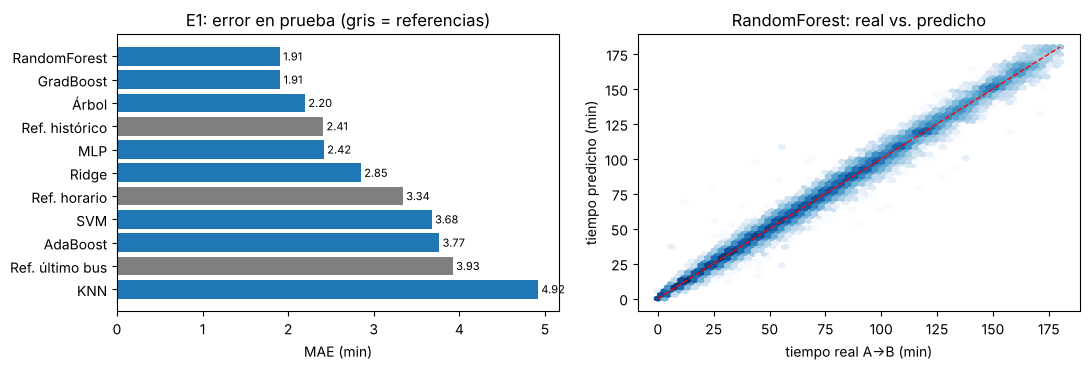

In [13]:
e = E1.sort_values("MAE")
best = e[~e.modelo.str.startswith("Ref.")].modelo.iloc[0]
best_ref = e[e.modelo.str.startswith("Ref.")].modelo.iloc[0]
print("mejor modelo:", best, "| mejor referencia:", best_ref)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].barh(e.modelo, e.MAE, color=["tab:gray" if m_.startswith("Ref.") else "tab:blue" for m_ in e.modelo])
axes[0].invert_yaxis()
for i, v in enumerate(e.MAE):
    axes[0].text(v, i, f" {v:.2f}", va="center", fontsize=8)
axes[0].set(xlabel="MAE (min)", title="E1: error en prueba (gris = referencias)")
axes[1].hexbin(d_te.y, PRED[best], gridsize=60, bins="log", cmap="Blues", extent=(0, 180, 0, 180))
axes[1].plot([0, 180], [0, 180], "r--", lw=1)
axes[1].set(xlabel="tiempo real A→B (min)", ylabel="tiempo predicho (min)", title=f"{best}: real vs. predicho")
fig.tight_layout(); fig.savefig(FIG / "exp1_comparacion.png", dpi=200); plt.show()

## E2. Error según el horizonte Δ (distancia de A a B)
Con el modelo único de E1 se desagrega el error de prueba por Δ. Se reporta la mejora de cada modelo
frente a la **mejor referencia en ese Δ**.

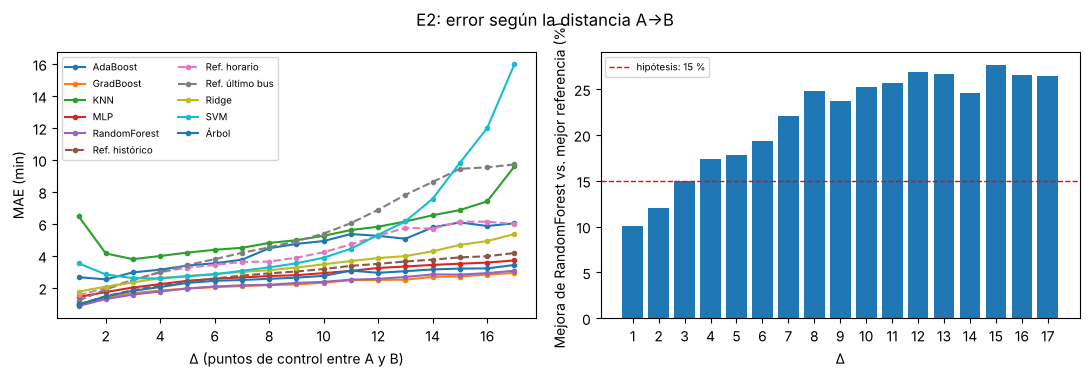

,AdaBoost,GradBoost,KNN,MLP,RandomForest,Ref. histórico,Ref. horario,Ref. último bus,Ridge,SVM,Árbol,mejora_RandomForest_%
delta,,,,,,,,,,,,
1,2.66,0.97,6.48,1.42,0.86,0.95,1.53,1.19,1.76,3.53,0.95,10.0
2,2.52,1.37,4.15,1.73,1.29,1.47,1.99,1.89,2.07,2.83,1.46,12.0
3,2.96,1.66,3.79,2.02,1.57,1.85,2.49,2.47,2.33,2.60,1.81,15.0
4,3.13,1.83,3.99,2.23,1.77,2.14,2.97,2.98,2.61,2.58,2.04,17.4
5,3.39,1.95,4.20,2.44,1.96,2.38,3.26,3.42,2.72,2.72,2.30,17.8
6,3.53,2.04,4.37,2.57,2.08,2.58,3.43,3.79,2.86,2.84,2.43,19.3
7,3.75,2.11,4.50,2.64,2.15,2.76,3.61,4.19,2.99,3.06,2.49,22.0
8,4.47,2.17,4.80,2.73,2.18,2.90,3.64,4.52,3.10,3.27,2.56,24.8
9,4.74,2.21,4.98,2.78,2.30,3.02,3.88,4.92,3.26,3.53,2.63,23.7


In [14]:
E2 = []
for D in DELTAS:
    msk = (d_te.delta == D).to_numpy()
    for name, yhat in PRED.items():
        E2.append({"delta": D, "modelo": name, "n": int(msk.sum()), **metrics(d_te.y[msk], yhat[msk])})
E2 = pd.DataFrame(E2)
mae_d = E2.pivot_table(index="delta", columns="modelo", values="MAE")
refs = [c for c in mae_d.columns if c.startswith("Ref.")]
mejora_d = 100 * (1 - mae_d[best].div(mae_d[refs].min(axis=1)))
E2.to_csv(RES / "E2_horizonte.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name in mae_d.columns:
    axes[0].plot(mae_d.index, mae_d[name], "o--" if name.startswith("Ref.") else "o-", ms=3, label=name)
axes[0].set(xlabel="Δ (puntos de control entre A y B)", ylabel="MAE (min)")
axes[0].legend(fontsize=7, ncol=2)
axes[1].bar(mejora_d.index, mejora_d, color="tab:blue")
axes[1].axhline(15, color="red", ls="--", lw=1, label="hipótesis: 15 %")
axes[1].set(xlabel="Δ", ylabel=f"Mejora de {best} vs. mejor referencia (%)", xticks=DELTAS)
axes[1].legend(fontsize=7)
fig.suptitle("E2: error según la distancia A→B")
fig.tight_layout(); fig.savefig(FIG / "exp2_horizonte.png", dpi=200); plt.show()
pd.concat([mae_d.round(2), mejora_d.round(1).rename(f"mejora_{best}_%")], axis=1)

## E3. Ablación de grupos de variables (Gradient Boosting, A→B)

In [15]:
ABL = {"todas": NUM,
       "sin buses recientes": [c for c in NUM if c not in G_REC],
       "sin GPS": [c for c in NUM if c not in G_GPS],
       "sin DBSCAN": [c for c in NUM if c not in G_DB],
       "sin clima": [c for c in NUM if c not in G_CLIMA],
       "sin altitud": [c for c in NUM if c not in G_ALT],
       "sin estado del bus i": [c for c in NUM if c not in G_I],
       "solo contexto": G_CTX}
E3 = pd.DataFrame([{"variables": lab, "n_variables": len(cols),
                    **evaluate("GradBoost", BEST_PRM["GradBoost"], d_trva, d_te, cols)[2]}
                   for lab, cols in ABL.items()])
E3.to_csv(RES / "E3_ablacion.csv", index=False)
E3.round(3)

,variables,n_variables,MAE,RMSE,WAPE_%,dentro_2min_%,P90_error,t_fit_s,t_pred_s
0,todas,28,1.909,2.732,3.269,65.152,4.198,87.220,3.375
1,sin buses recientes,25,1.979,2.856,3.389,64.143,4.315,82.664,2.985
2,sin GPS,24,1.909,2.734,3.269,65.211,4.195,82.301,3.142
3,sin DBSCAN,25,1.910,2.735,3.270,65.152,4.203,83.593,3.250
4,sin clima,22,1.883,2.699,3.224,65.892,4.147,79.184,3.123
5,sin altitud,26,1.919,2.738,3.286,64.888,4.212,83.580,3.564
6,sin estado del bus i,23,2.080,2.915,3.562,60.809,4.548,73.622,3.099
7,solo contexto,5,2.090,2.953,3.580,60.989,4.577,53.291,2.749


## E4. Reducción de dimensionalidad con PCA (KNN y SVM, A→B)
PCA conserva el 95 % de la varianza después de estandarizar y aplicar one-hot.

In [16]:
E4 = []
for name in ("KNN", "SVM"):
    for pca in (False, True):
        pipe, _, sc = evaluate(name, BEST_PRM[name], d_trva, d_te, NUM, pca=pca)
        ncomp = pipe.named_steps["pca"].n_components_ if pca else len(pipe.named_steps["prep"].get_feature_names_out())
        E4.append({"modelo": name, "PCA": pca, "dimensiones": ncomp, **sc})
E4 = pd.DataFrame(E4)
E4.to_csv(RES / "E4_pca.csv", index=False)
E4.round(3)

,modelo,PCA,dimensiones,MAE,RMSE,WAPE_%,dentro_2min_%,P90_error,t_fit_s,t_pred_s
0,KNN,False,73,4.921,6.558,8.427,26.887,10.168,0.401,51.848
1,KNN,True,21,5.083,6.817,8.705,26.400,10.509,0.500,34.623
2,SVM,False,73,3.680,6.302,6.302,43.919,7.785,4.448,87.316
3,SVM,True,21,4.117,6.832,7.050,39.191,8.700,2.831,54.496


## E5. Sensibilidad a hiperparámetros y costo computacional
Cada combinación evaluada en validación está en `resultados/E5_busqueda_hiperparametros.csv`.
Se resume cuánto cambia el MAE de validación según los hiperparámetros y los tiempos del modelo final.

In [17]:
S = pd.concat(SEARCH)
E5 = pd.concat([S.groupby("modelo").MAE.agg(["min", "max", "std"]).add_prefix("MAE_val_"),
                E1.set_index("modelo")[["t_fit_s", "t_pred_s"]]], axis=1).dropna(subset=["MAE_val_min"])
E5.to_csv(RES / "E5_resumen.csv")
E5.round(3)

,MAE_val_min,MAE_val_max,MAE_val_std,t_fit_s,t_pred_s
modelo,,,,,
AdaBoost,3.879,4.851,0.419,86.946,2.464
GradBoost,2.439,2.511,0.026,88.408,3.276
KNN,5.858,6.316,0.186,0.405,52.377
MLP,3.030,3.345,0.132,13.957,0.212
RandomForest,2.450,2.608,0.076,643.785,2.173
Ridge,3.497,3.508,0.005,1.900,0.115
SVM,4.193,26.499,8.008,4.201,84.311
Árbol,2.744,3.727,0.478,10.998,0.163


## E6. Análisis de errores y prueba estadística
Error absoluto del mejor modelo frente a la mejor referencia, por tramo y por hora. La prueba de
Wilcoxon (unilateral) compara el MAE por bloques día × tramo del conjunto de prueba.

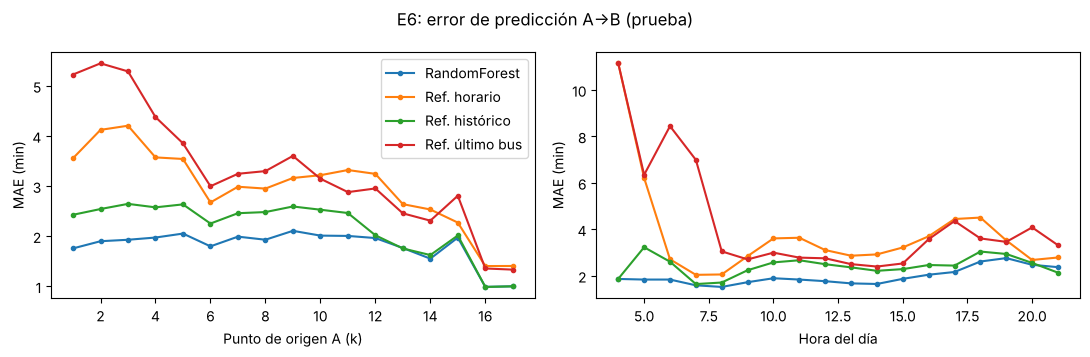

,comparación,bloques,MAE_modelo,MAE_ref,mejora_%,p_valor
0,RandomForest vs. Ref. horario,918,1.9634,3.5028,43.9472,0.0
1,RandomForest vs. Ref. histórico,918,1.9634,2.5137,21.8905,0.0
2,RandomForest vs. Ref. último bus,918,1.9634,4.0364,51.3574,0.0


In [18]:
err = d_te[["date", "k", "delta", "hour"]].copy()
err["hora"] = err.hour.astype(int)
for lab in (best, "Ref. horario", "Ref. histórico", "Ref. último bus"):
    err[lab] = np.abs(d_te.y.to_numpy() - PRED[lab])
cols = [best, "Ref. horario", "Ref. histórico", "Ref. último bus"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, lab in ((axes[0], "k", "Punto de origen A (k)"), (axes[1], "hora", "Hora del día")):
    g_ = err.groupby(col)
    g_[cols].mean()[g_.size() >= 30].plot(ax=ax, marker="o", ms=3)   # horas con pocos datos son ruido
    ax.set(xlabel=lab, ylabel="MAE (min)")
axes[1].get_legend().remove()
fig.suptitle("E6: error de predicción A→B (prueba)")
fig.tight_layout(); fig.savefig(FIG / "exp6_errores.png", dpi=200); plt.show()

blk = err.groupby(["date", "k", "delta"])[cols].mean()   # bloques día × origen × Δ
W = []
for ref in cols[1:]:
    _, pval = wilcoxon(blk[best], blk[ref], alternative="less")
    W.append({"comparación": f"{best} vs. {ref}", "bloques": len(blk), "MAE_modelo": blk[best].mean(),
              "MAE_ref": blk[ref].mean(), "mejora_%": 100 * (1 - blk[best].mean() / blk[ref].mean()), "p_valor": pval})
W = pd.DataFrame(W)
W.to_csv(RES / "E6_wilcoxon.csv", index=False)
W.round(4)

## Resumen para el informe
Hipótesis (V1): en la predicción del tiempo de llegada de A a B, el mejor modelo reduce el MAE global
en al menos 15 % frente a la mejor referencia. Además se reporta desde qué Δ se cumple.

In [19]:
mae = E1.set_index("modelo").MAE
mejora = 100 * (1 - mae[best] / mae[best_ref])
print(f"A→B (todos los Δ) | {best}: MAE {mae[best]:.2f} min | mejor referencia ({best_ref}): {mae[best_ref]:.2f} min "
      f"| mejora {mejora:.1f} % -> hipótesis {'confirmada' if mejora >= 15 else 'no confirmada'}")
cumple = mejora_d[mejora_d >= 15]
print(f"la mejora supera 15 % en Δ = {list(cumple.index)}; Δ = 1: {mejora_d.loc[1]:.1f} %")
print("archivos:", sorted(str(x) for x in list(RES.iterdir()) + list(MOD.iterdir())))

A→B (todos los Δ) | RandomForest: MAE 1.91 min | mejor referencia (Ref. histórico): 2.41 min | mejora 20.9 % -> hipótesis confirmada
la mejora supera 15 % en Δ = [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]; Δ = 1: 10.0 %
archivos: ['modelos/eta_GradBoost_AaB.joblib', 'modelos/eta_RandomForest_AaB.joblib', 'resultados/E1_eta_AaB.csv', 'resultados/E1_eta_delta1.csv', 'resultados/E2_horizonte.csv', 'resultados/E3_ablacion.csv', 'resultados/E4_pca.csv', 'resultados/E5_busqueda_hiperparametros.csv', 'resultados/E5_resumen.csv', 'resultados/E6_wilcoxon.csv', 'resultados/dataset_modelo.pkl', 'resultados/paraderos_dbscan.csv', 'resultados/puntos_control.csv']
